In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data=pd.read_csv(r"C:\Users\acer\Desktop\archive (1)\SampleSuperstore.csv")
print(data.head()) # first 5 rows

        Ship Mode    Segment        Country             City       State  \
0    Second Class   Consumer  United States        Henderson    Kentucky   
1    Second Class   Consumer  United States        Henderson    Kentucky   
2    Second Class  Corporate  United States      Los Angeles  California   
3  Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4  Standard Class   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region         Category Sub-Category     Sales  Quantity  \
0        42420  South        Furniture    Bookcases  261.9600         2   
1        42420  South        Furniture       Chairs  731.9400         3   
2        90036   West  Office Supplies       Labels   14.6200         2   
3        33311  South        Furniture       Tables  957.5775         5   
4        33311  South  Office Supplies      Storage   22.3680         2   

   Discount    Profit  
0      0.00   41.9136  
1      0.00  219.5820  
2      0.00    6.871

In [3]:
data.columns #cols name list


Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [4]:
data.tail()  # last 5 rows

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.248,3,0.2,4.1028
9990,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.960,2,0.0,15.6332
9991,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.576,2,0.2,19.3932
9992,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,29.600,4,0.0,13.3200
9993,Second Class,Consumer,United States,Westminster,California,92683,West,Office Supplies,Appliances,243.160,2,0.0,72.9480


In [5]:
data.info        #data types+non-null counts 
data.describe    #numeric cols stats

<bound method NDFrame.describe of            Ship Mode    Segment        Country             City       State  \
0       Second Class   Consumer  United States        Henderson    Kentucky   
1       Second Class   Consumer  United States        Henderson    Kentucky   
2       Second Class  Corporate  United States      Los Angeles  California   
3     Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4     Standard Class   Consumer  United States  Fort Lauderdale     Florida   
...              ...        ...            ...              ...         ...   
9989    Second Class   Consumer  United States            Miami     Florida   
9990  Standard Class   Consumer  United States       Costa Mesa  California   
9991  Standard Class   Consumer  United States       Costa Mesa  California   
9992  Standard Class   Consumer  United States       Costa Mesa  California   
9993    Second Class   Consumer  United States      Westminster  California   

      Postal Code

In [6]:
# data cleaning
data.isnull().sum() # true/false matrix(null-true,no-false)


Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

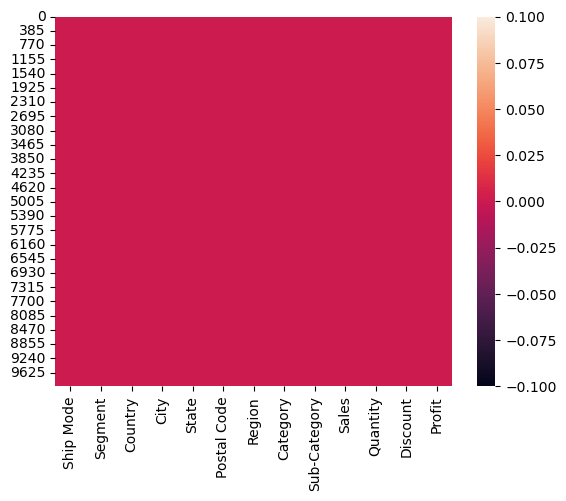

In [7]:
sns.heatmap(data.isnull())  # data color grid=row & cols box (null check)
plt.show

In [8]:
null_percentage=(data.isnull().sum() / len(data)) * 100    #null count/total row * 100
print(null_percentage)

Ship Mode       0.0
Segment         0.0
Country         0.0
City            0.0
State           0.0
Postal Code     0.0
Region          0.0
Category        0.0
Sub-Category    0.0
Sales           0.0
Quantity        0.0
Discount        0.0
Profit          0.0
dtype: float64


In [9]:
data.dropna()                  # null having rows are droped(new copies are return)
data.dropna(inplace=True)      # orginal data change permanent and update 
data.dropna(axis=1)            # remove null cols are drop


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


In [10]:
mean_profit=data["Profit"].mean()   #give variable= profit cols null values are filled with avg value
data["Profit"]=data ["Profit"].fillna(mean_profit)
data["Profit"].isnull().sum()

np.int64(0)

In [11]:
data["Sales"]=data["Sales"].ffill()  # previous row value copy and fill
data["Category"]=data["Category"].bfill() # next row value copy and fill
data.isnull().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [12]:
data.duplicated().sum()               #duplicate rows count
data.drop_duplicates(inplace=True)    #duplicatee remove 
data.duplicated().sum()

np.int64(0)

In [13]:
# filteration 
# Single condition
data[data['Sales'] > 500]              # Sales 500-ku periya rows mattum


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
7,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Technology,Phones,907.1520,6,0.20,90.7152
10,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Furniture,Tables,1706.1840,9,0.20,85.3092
11,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Technology,Phones,911.4240,4,0.20,68.3568
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9931,Standard Class,Consumer,United States,San Bernardino,California,92404,West,Furniture,Bookcases,683.3320,4,0.15,-40.1960
9942,Standard Class,Consumer,United States,Anaheim,California,92804,West,Office Supplies,Storage,998.8200,9,0.00,29.9646
9947,Second Class,Corporate,United States,Indianapolis,Indiana,46203,Central,Furniture,Chairs,1925.8800,6,0.00,539.2464
9948,Second Class,Corporate,United States,Indianapolis,Indiana,46203,Central,Office Supplies,Appliances,2405.2000,8,0.00,793.7160


In [14]:
#Multiple conditions (AND)
data[(data['Sales'] > 500) & (data['Region'] == 'West')] 

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
7,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Technology,Phones,907.152,6,0.20,90.7152
10,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Furniture,Tables,1706.184,9,0.20,85.3092
11,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Technology,Phones,911.424,4,0.20,68.3568
24,Standard Class,Consumer,United States,Orem,Utah,84057,West,Furniture,Tables,1044.630,3,0.00,240.2649
67,Standard Class,Corporate,United States,Gilbert,Arizona,85234,West,Office Supplies,Art,1113.024,8,0.20,111.3024
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9857,Standard Class,Corporate,United States,Seattle,Washington,98103,West,Furniture,Tables,3393.680,8,0.00,610.8624
9907,First Class,Corporate,United States,Anaheim,California,92804,West,Furniture,Chairs,717.720,3,0.20,71.7720
9929,Same Day,Consumer,United States,San Francisco,California,94122,West,Technology,Copiers,2799.960,5,0.20,944.9865
9931,Standard Class,Consumer,United States,San Bernardino,California,92404,West,Furniture,Bookcases,683.332,4,0.15,-40.1960


In [15]:
# Multiple conditions (OR)
data[(data['Sub-Category'] == 'Chairs') | (data['Sub-Category'] == 'Tables')]

# NOT condition
data[data['Quantity'] != 2]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
5,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Furniture,Furnishings,48.8600,7,0.00,14.1694
6,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Office Supplies,Art,7.2800,4,0.00,1.9656
7,Standard Class,Consumer,United States,Los Angeles,California,90032,West,Technology,Phones,907.1520,6,0.20,90.7152
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9986,Standard Class,Consumer,United States,Los Angeles,California,90008,West,Technology,Accessories,36.2400,1,0.00,15.2208
9987,Standard Class,Corporate,United States,Athens,Georgia,30605,South,Technology,Accessories,79.9900,1,0.00,28.7964
9988,Standard Class,Corporate,United States,Athens,Georgia,30605,South,Technology,Phones,206.1000,5,0.00,55.6470
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028


In [16]:
data[data['City'].str.contains('New York')]   #check city col to show new york 
data[data['City'].str.contains('new york', case=False)] #capital or small all match show


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
53,Standard Class,Corporate,United States,New York City,New York,10024,East,Office Supplies,Fasteners,15.260,7,0.0,6.2566
54,Standard Class,Corporate,United States,New York City,New York,10024,East,Technology,Phones,1029.950,5,0.0,298.6855
70,Standard Class,Consumer,United States,New York City,New York,10009,East,Office Supplies,Binders,4.616,1,0.2,1.7310
96,Second Class,Home Office,United States,New York City,New York,10009,East,Furniture,Furnishings,96.530,7,0.0,40.5426
110,Standard Class,Corporate,United States,New York City,New York,10035,East,Furniture,Furnishings,41.960,2,0.0,10.9096
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9926,First Class,Corporate,United States,New York City,New York,10035,East,Technology,Phones,199.980,2,0.0,53.9946
9927,First Class,Corporate,United States,New York City,New York,10035,East,Office Supplies,Storage,83.920,4,0.0,20.1408
9938,Standard Class,Corporate,United States,New York City,New York,10009,East,Furniture,Furnishings,60.350,5,0.0,19.9155
9939,Standard Class,Corporate,United States,New York City,New York,10009,East,Office Supplies,Supplies,35.520,4,0.0,9.9456


In [17]:
# sort_value & groupby
data.groupby("Region")[["Sales","Profit"]].sum()                                          # total sales and profit in region 
data.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Profit",ascending=False)   # in region - sales and profit cols sum and profit high region show in arrange

,Sales,Profit
Region,,
West,725255.6365,108329.8079
East,678435.1960,91506.3092
South,391721.9050,46749.4303
Central,500782.8528,39655.8752


In [18]:
data.groupby("Sub-Category")[["Sales", "Profit"]].sum().nlargest(5, "Profit")    # In category wise sales and profit calculate,then profit of top 10

,Sales,Profit
Sub-Category,,
Copiers,149528.030,55617.8249
Phones,330007.054,44515.7306
Accessories,167380.318,41936.6357
Paper,78224.142,33944.2395
Binders,203409.169,30228.0003


In [19]:
# (discount high in profit loss check)
discount_profit=data.groupby("Sub-Category")[["Discount","Profit"]].mean().sort_values("Profit") #sub-category wise group-discount & profit avg takes and profit in ascending[gives-high discount,low]
print(discount_profit)

              Discount      Profit
Sub-Category                      
Tables        0.261285  -55.565771
Bookcases     0.211140  -15.230509
Supplies      0.076842   -6.258418
Fasteners     0.082028    4.375660
Art           0.074969    8.207059
Furnishings   0.138494   13.653476
Labels        0.068871   15.224193
Binders       0.372011   19.860710
Paper         0.074908   24.977365
Storage       0.074704   25.152277
Envelopes     0.080315   27.418019
Machines      0.306087   29.432669
Appliances    0.166524   38.922758
Chairs        0.170244   43.198582
Phones        0.154556   50.073938
Accessories   0.078452   54.111788
Copiers       0.161765  817.909190


In [20]:
#loss_making sub-categories/region-solution
loss_making=data[data["Profit"]<0]
print("loss_making rows:", loss_making.shape[0])
print(loss_making.groupby("Sub-Category")["Profit"].sum())


loss_making rows: 1869
Sub-Category
Accessories     -930.6265
Appliances     -8629.6412
Binders       -38504.2594
Bookcases     -12152.2060
Chairs         -9868.7825
Fasteners        -33.1952
Furnishings    -6490.9134
Machines      -30118.6682
Phones         -7530.6235
Storage        -6426.3038
Supplies       -3015.6219
Tables        -32412.1483
Name: Profit, dtype: float64


C:\Users\acer\AppData\Local\Temp\ipykernel_25348\853406807.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_data.index, y=region_data.values, palette='viridis')


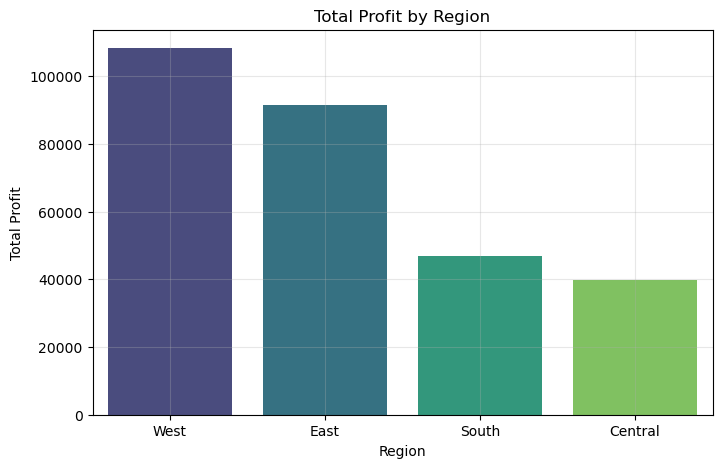

In [21]:
# VISUALIZATION

# 1. Region-wise Profit (Bar chart)

plt.figure(figsize=(8,5))
region_data = data.groupby('Region')['Profit'].sum().sort_values(ascending=False)
sns.barplot(x=region_data.index, y=region_data.values, palette='viridis')
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.grid(True, alpha=0.3) #start to end colours
plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_25348\4044515678.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Ship Mode', data=data, palette='pastel')


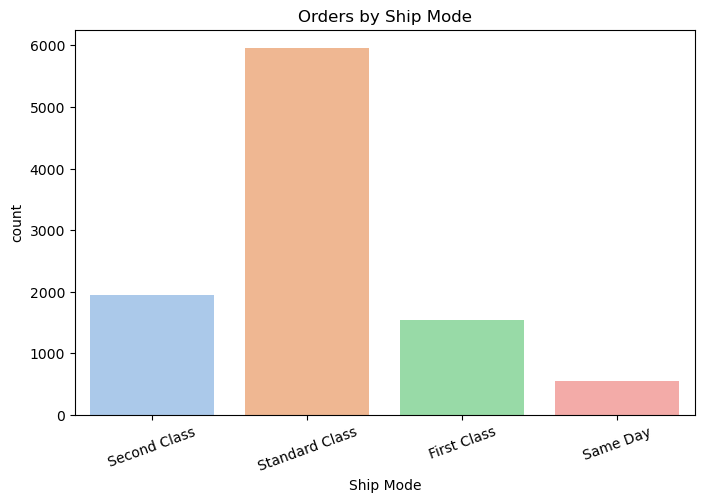

In [22]:
# 2. Count plot - Ship Mode frequency
plt.figure(figsize=(8,5))
sns.countplot(x='Ship Mode', data=data, palette='pastel')
plt.title("Orders by Ship Mode")
plt.xticks(rotation=20)
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_25348\3218689695.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_sub.values, y=top_sub.index, palette='coolwarm', orient="h")


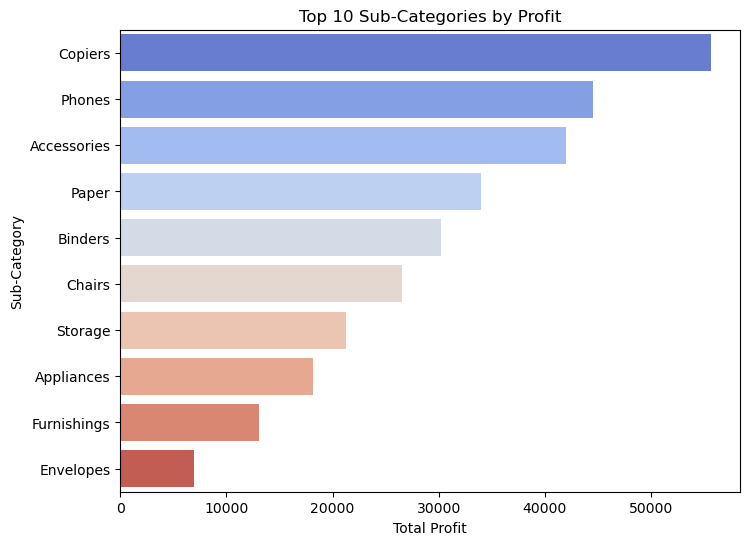

In [23]:

# 3. Horizontal bar - Top 10 Sub-Categories by Profit
plt.figure(figsize=(8,6))
top_sub = data.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_sub.values, y=top_sub.index, palette='coolwarm', orient="h")
plt.title("Top 10 Sub-Categories by Profit")
plt.xlabel("Total Profit")
plt.show()

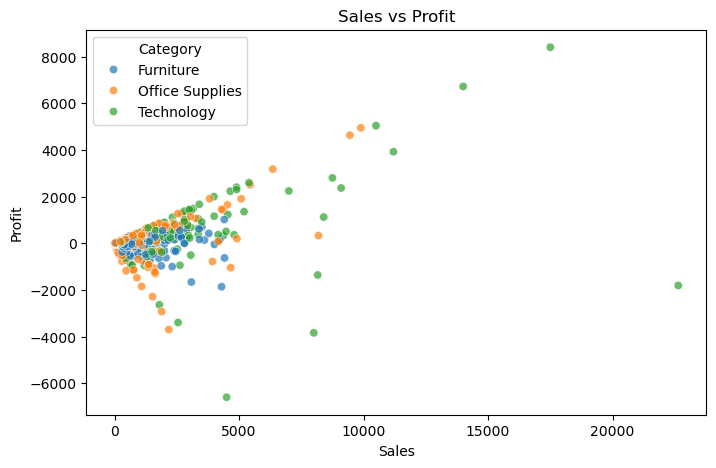

In [24]:

# 4. Scatter plot - Sales vs Profit
plt.figure(figsize=(8,5))
sns.scatterplot(x='Sales', y='Profit', data=data, hue='Category', alpha=0.7)
plt.title("Sales vs Profit")
plt.show()

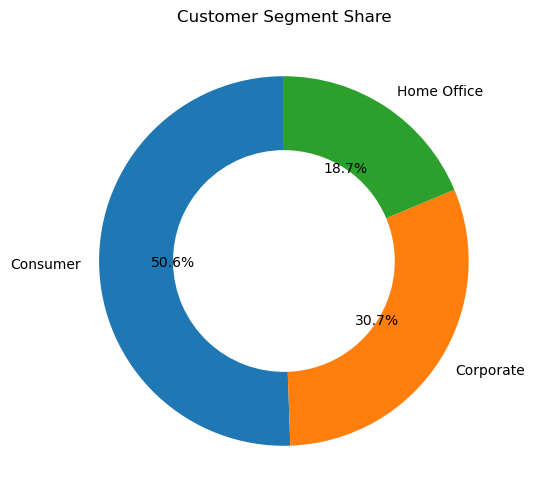

In [25]:

# 5. Pie chart - Segment share
plt.figure(figsize=(6,6))
segment_data=data.groupby("Segment")["Sales"].sum()
plt.pie(segment_data, labels=segment_data.index,autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.4))
plt.title("Customer Segment Share")
plt.ylabel('')
plt.show()

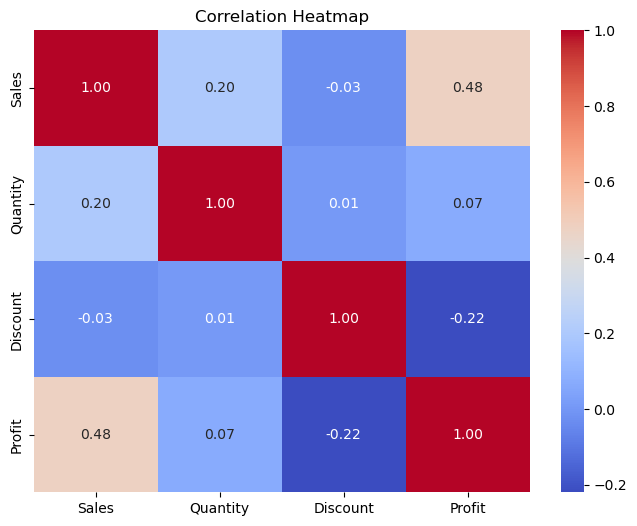

In [26]:
# 6. Heatmap - Correlation between numeric columns
plt.figure(figsize=(8,6))
sns.heatmap(data[['Sales','Quantity','Discount','Profit']].corr(), annot=True, cmap='coolwarm',fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

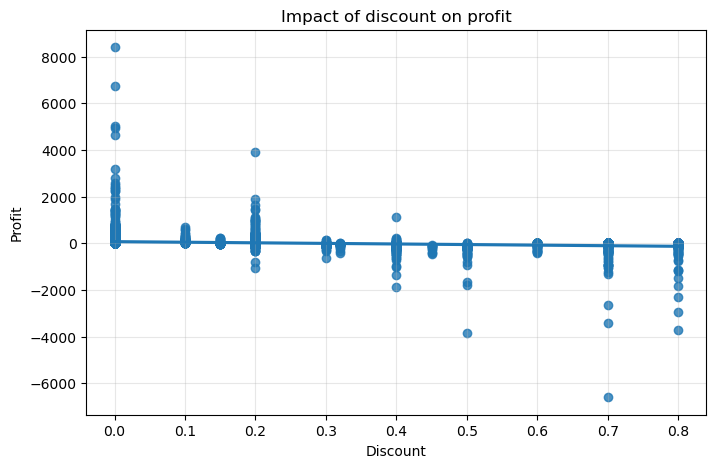

In [27]:
# 7. Histplot - Sales distribution
plt.figure(figsize=(8,5))
sns.regplot(data=data, x="Discount", y="Profit", line_kws={})
plt.title("Impact of discount on profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.grid(True, alpha=0.3)
plt.show()

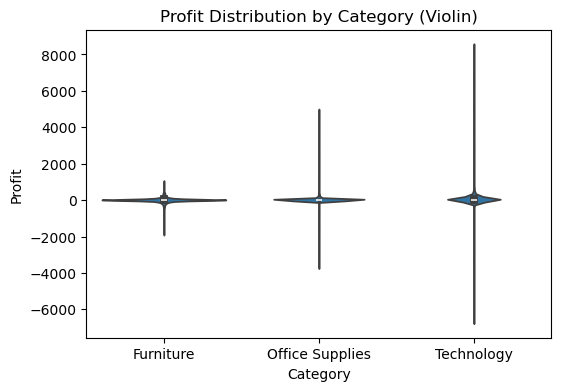

In [28]:
# 8.Violin plot - Profit spread by Category
plt.figure(figsize=(6,4))
sns.violinplot(data=data, x='Category', y='Profit')
plt.title("Profit Distribution by Category (Violin)")
plt.show()

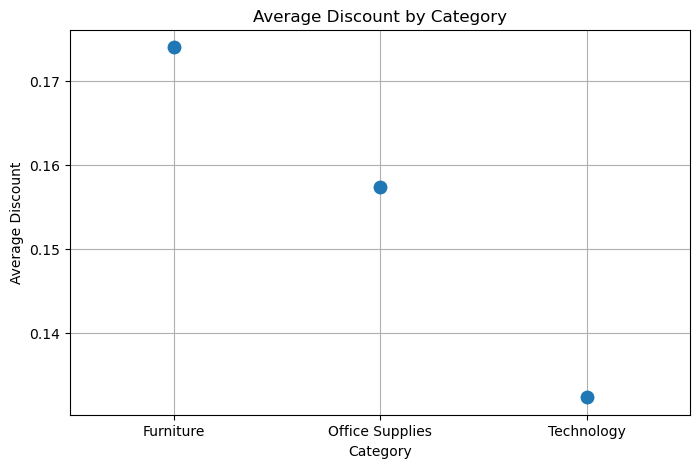

In [29]:
#9. Category vs Average Discount — sns.swarmplot()

avg_discount = data.groupby('Category', as_index=False)['Discount'].mean()
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=avg_discount,
    x='Category',
    y='Discount',
    size=10
)

plt.title('Average Discount by Category')
plt.xlabel('Category')
plt.ylabel('Average Discount')
plt.grid(True)
plt.show()



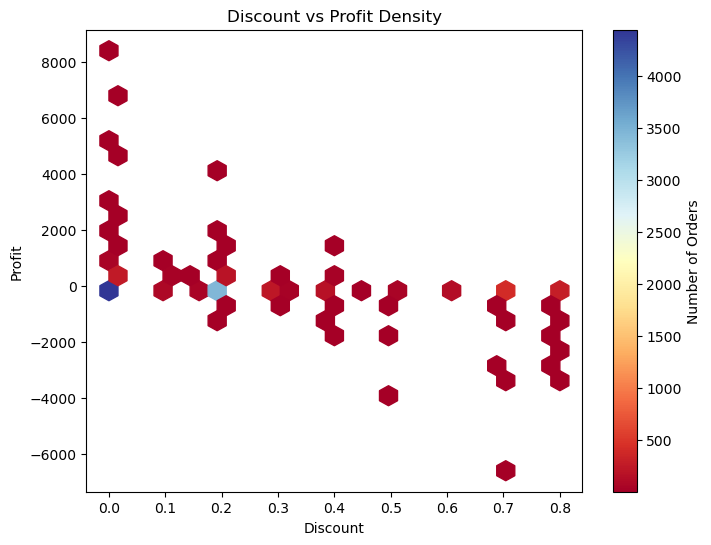

In [30]:
# 10

plt.figure(figsize=(8,6))
plt.hexbin(
    data['Discount'],
    data['Profit'],
    gridsize=25,
    cmap='RdYlBu',
    mincnt=1)

plt.colorbar(label='Number of Orders')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.title('Discount vs Profit Density')
plt.show()

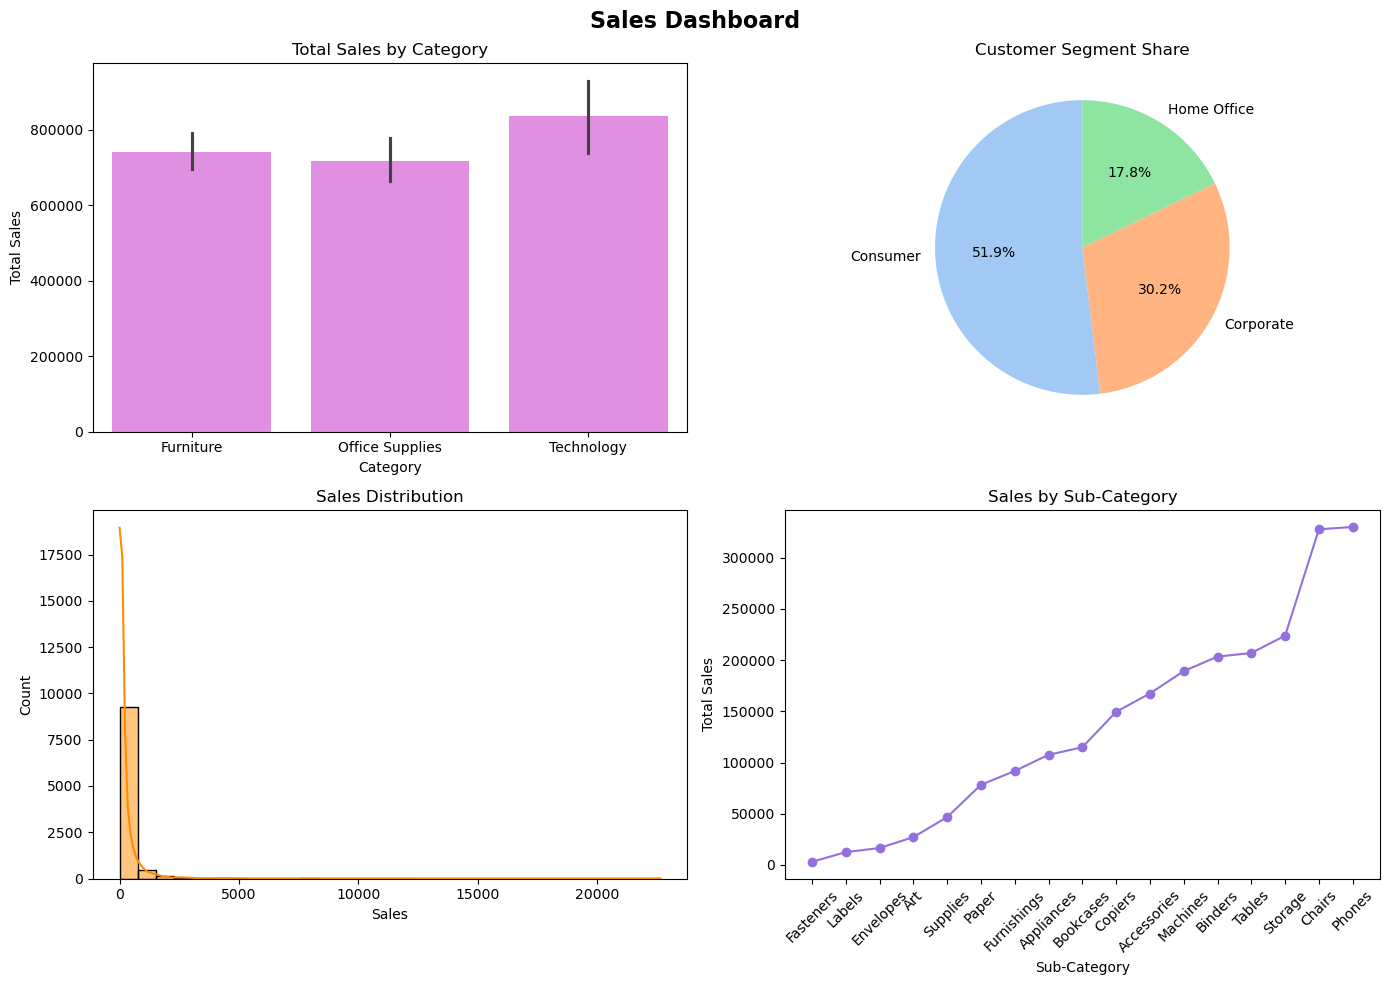

In [31]:


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 0,0 - BAR chart: Category wise total Sales evlo nu kaatum
sns.barplot(data=data, x='Category', y='Sales', estimator=sum, ax=axes[0,0], color='violet')
axes[0,0].set_title("Total Sales by Category")
axes[0,0].set_xlabel("Category")
axes[0,0].set_ylabel("Total Sales")

# 0,1 - PIE chart: Segment (Consumer/Corporate/Home Office) percentage share
segment_counts = data['Segment'].value_counts()
axes[0,1].pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', startangle=90,
              colors=sns.color_palette('pastel'))
axes[0,1].set_title("Customer Segment Share")

# 1,0 - HISTOGRAM: Sales values eppadi spread aayirukku (evlo orders low sales, evlo high sales)
sns.histplot(data=data, x='Sales', bins=30, kde=True, ax=axes[1,0], color='darkorange')
axes[1,0].set_title("Sales Distribution")
axes[1,0].set_xlabel("Sales")
axes[1,0].set_ylabel("Count")

# 1,1 - LINE chart: Sub-Category wise total Sales - trend maadhiri kaatum
# (Order Date illa dataset-la, so Sub-Category-a x-axis use pannirom)
subcat_sales = data.groupby('Sub-Category')['Sales'].sum().sort_values()
axes[1,1].plot(subcat_sales.index, subcat_sales.values, color='mediumpurple', marker='o')
axes[1,1].set_title("Sales by Sub-Category")
axes[1,1].set_xlabel("Sub-Category")
axes[1,1].set_ylabel("Total Sales")
axes[1,1].tick_params(axis='x', rotation=45)

plt.suptitle("Sales Dashboard", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

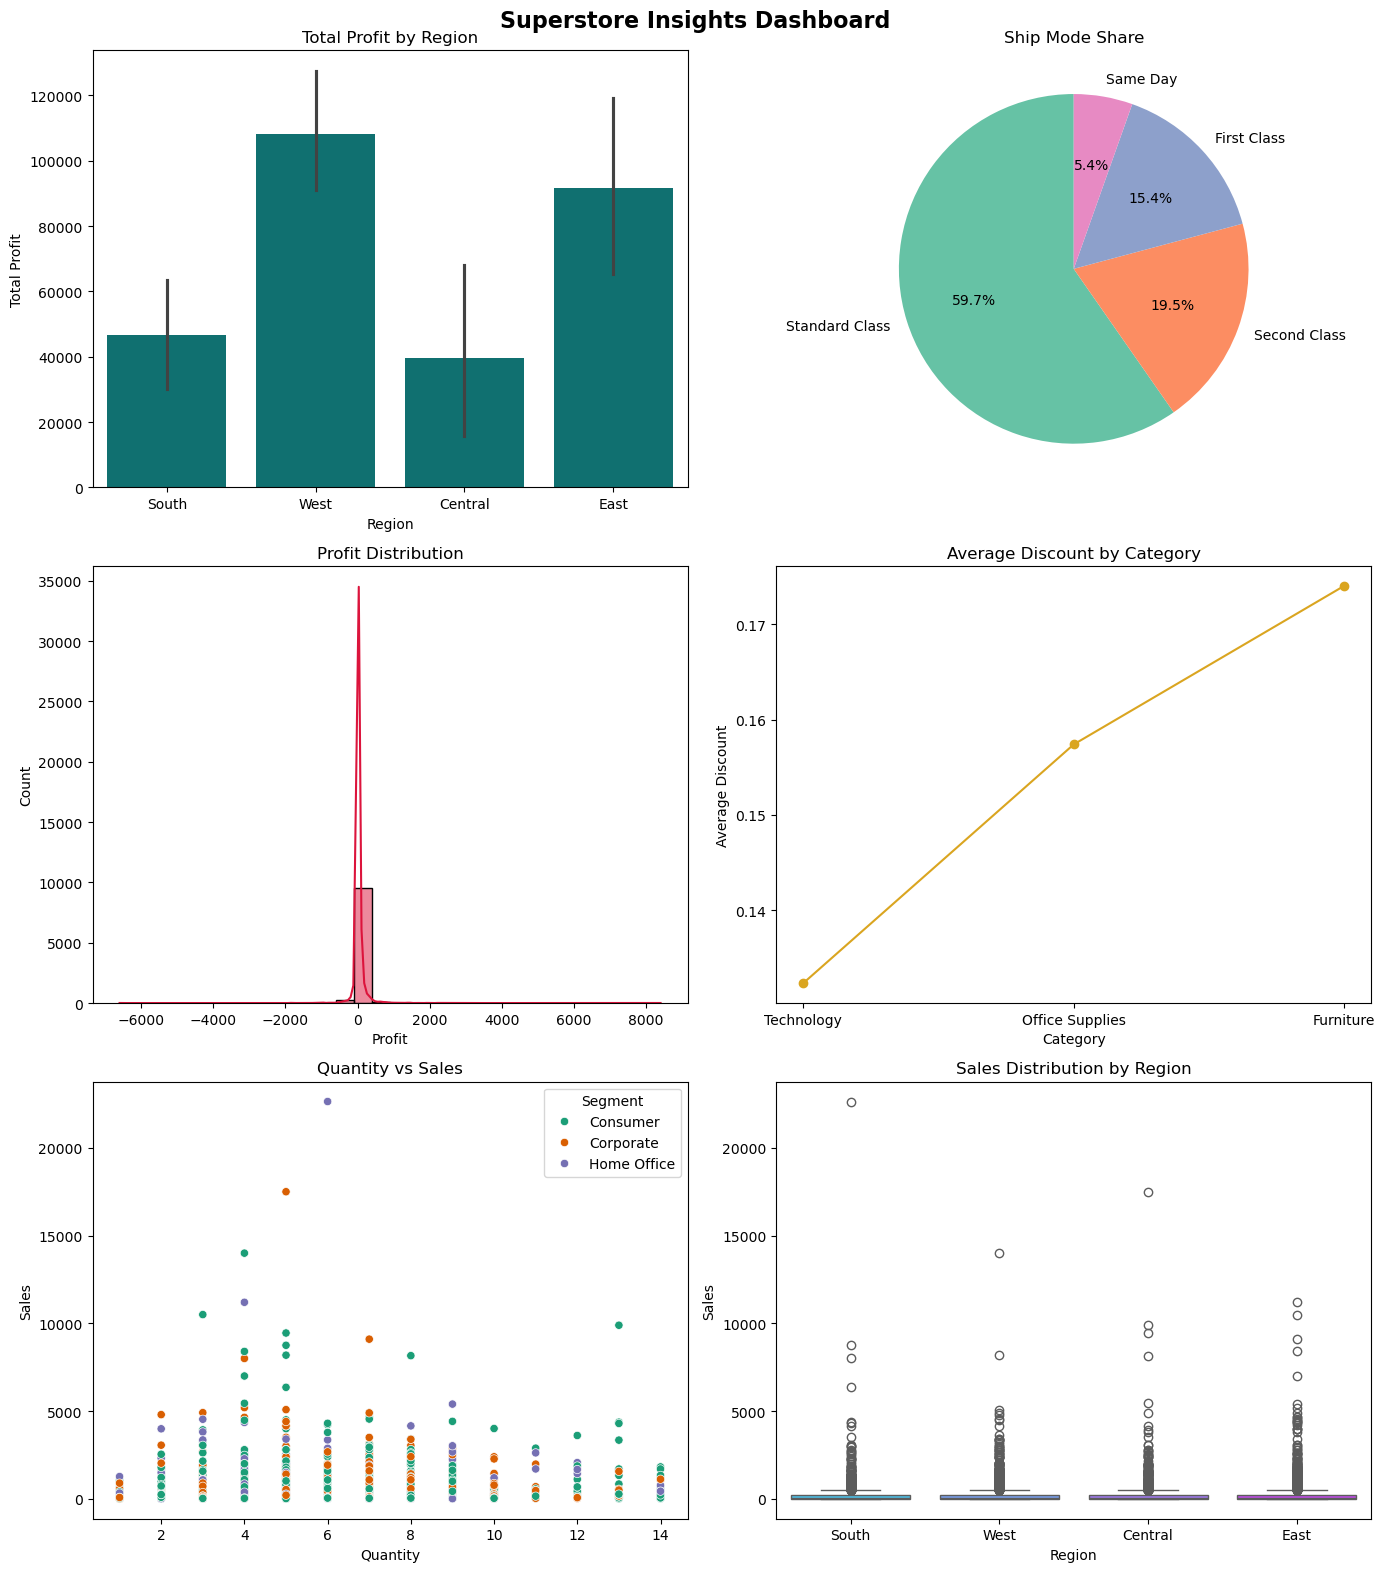

In [33]:

fig, axes = plt.subplots(3, 2, figsize=(14, 16))

# 0,0 - BAR: Region vaari total Profit
sns.barplot(data=data, x='Region', y='Profit', estimator=sum, ax=axes[0,0], color='teal')
axes[0,0].set_title("Total Profit by Region")
axes[0,0].set_xlabel("Region")
axes[0,0].set_ylabel("Total Profit")

# 0,1 - PIE: Ship Mode share
ship_counts = data['Ship Mode'].value_counts()
axes[0,1].pie(ship_counts, labels=ship_counts.index, autopct='%1.1f%%', startangle=90,
              colors=sns.color_palette('Set2'))
axes[0,1].set_title("Ship Mode Share")

# 1,0 - HISTOGRAM: Profit distribution (loss vs profit orders evlo)
sns.histplot(data=data, x='Profit', bins=30, kde=True, ax=axes[1,0], color='crimson')
axes[1,0].set_title("Profit Distribution")
axes[1,0].set_xlabel("Profit")
axes[1,0].set_ylabel("Count")

# 1,1 - LINE: Category vaari average Discount trend
cat_discount = data.groupby('Category')['Discount'].mean().sort_values()
axes[1,1].plot(cat_discount.index, cat_discount.values, color='goldenrod', marker='o')
axes[1,1].set_title("Average Discount by Category")
axes[1,1].set_xlabel("Category")
axes[1,1].set_ylabel("Average Discount")

# 2,0 - SCATTER: Quantity vs Sales
sns.scatterplot(data=data, x='Quantity', y='Sales', hue='Segment', palette='Dark2', ax=axes[2,0])
axes[2,0].set_title("Quantity vs Sales")
axes[2,0].set_xlabel("Quantity")
axes[2,0].set_ylabel("Sales")

# 2,1 - BOXPLOT: Region vaari Sales spread
sns.boxplot(data=data, x='Region', y='Sales', hue='Region', palette='cool', legend=False, ax=axes[2,1])
axes[2,1].set_title("Sales Distribution by Region")
axes[2,1].set_xlabel("Region")
axes[2,1].set_ylabel("Sales")

plt.suptitle("Superstore Insights Dashboard", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()